# Previsione della resa del grano duro
Una cooperativa cerealicola vuole stimare a fine aprile la resa del grano duro di ogni campo dei soci, per organizzare in anticipo stoccaggio e vendite. Vengono forniti i dati simulati di 60 campi dal 2018 al 2025.

# 1. ============== CARICARE E ISPEZIONARE LE TABELLE ==============

In [42]:
# Import delle librerie
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

In [43]:
# Caricare le tabelle
campagne_grano = pd.read_csv("dati/campagne_grano.csv")
campi = pd.read_csv("dati/campi.csv")

# Unire le due tabelle
campi_grano = pd.merge(campagne_grano, campi, on="id_campo", how="left")

# Ispezionare la tabella
print("Struttura tabella campi_grano:")
print(campi_grano.info())

# Ispezionare il numero di valori nulli
print("Valori nulli per colonna:")
print(campi_grano.isna().sum())

# Ispezionare la presenza di righe duplicate
print(f'\nNumero di righe duplicate: {campi_grano.duplicated().sum()}')

Struttura tabella campi_grano:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_campo               410 non-null    object 
 1   anno                   410 non-null    int64  
 2   varieta                410 non-null    object 
 3   azoto_kg_ha            410 non-null    int64  
 4   pioggia_nov_apr_mm     410 non-null    float64
 5   tmax_media_apr_mag     410 non-null    float64
 6   ndvi_max_apr           396 non-null    float64
 7   proteina_granella_pct  410 non-null    float64
 8   data_raccolta          410 non-null    object 
 9   resa_t_ha              410 non-null    float64
 10  comune                 410 non-null    object 
 11  tessitura              410 non-null    object 
 12  ettari                 410 non-null    int64  
dtypes: float64(5), int64(3), object(5)
memory usage: 41.8+ KB
None
Valori nulli per

# La colonna NDVI_max_apr presenta 14 valori mancanti.

In [44]:
# Ispezionare le righe con valori di NDVI mancanti
NDVI_mancanti = campi_grano[campi_grano["ndvi_max_apr"].isna()]
NDVI_mancanti

,id_campo,anno,varieta,azoto_kg_ha,pioggia_nov_apr_mm,tmax_media_apr_mag,ndvi_max_apr,proteina_granella_pct,data_raccolta,resa_t_ha,comune,tessitura,ettari
20,F023,2018,Iride,80,431.0,21.6,NaN,13.7,2018-06-14,4.13,Sanluri,argilloso,25
67,F016,2019,Iride,60,351.0,22.7,NaN,13.5,2019-06-06,3.45,Alghero,franco,4
70,F019,2019,Iride,140,341.0,22.9,NaN,14.4,2019-06-10,4.39,Villacidro,franco,45
77,F026,2019,Antalis,120,324.0,21.1,NaN,13.7,2019-06-13,4.57,Villacidro,franco,46
160,F059,2020,Iride,80,283.0,21.8,NaN,13.8,2020-06-16,3.69,Alghero,argilloso,19
173,F020,2021,Iride,120,353.0,21.5,NaN,13.9,2021-06-14,3.81,Sanluri,sabbioso,49
186,F038,2021,Iride,140,381.0,21.3,NaN,14.4,2021-06-27,4.46,Villacidro,franco,35
240,F040,2022,Iride,120,265.0,21.1,NaN,14.0,2022-06-07,4.40,Ozieri,franco,30
241,F041,2022,Antalis,60,268.0,22.5,NaN,13.4,2022-06-08,3.52,Villacidro,franco,58
262,F006,2023,Iride,120,360.0,21.1,NaN,13.5,2023-06-14,5.09,Sanluri,franco,20


# Le 14 righe prive di valori NDVI per copertura nuvolosa verranno escluse.

# 2. ============== PULIRE LA TABELLA ==============

In [45]:
# Eliminare le 14 righe con valori NDVI mancanti
campi_grano_pulito = campi_grano.dropna()
print("Struttura tabella dopo l'eliminazione delle 14 righe con valori mancanti:")
print(campi_grano_pulito.info())

Struttura tabella dopo l'eliminazione delle 14 righe con valori mancanti:
<class 'pandas.core.frame.DataFrame'>
Index: 396 entries, 0 to 409
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_campo               396 non-null    object 
 1   anno                   396 non-null    int64  
 2   varieta                396 non-null    object 
 3   azoto_kg_ha            396 non-null    int64  
 4   pioggia_nov_apr_mm     396 non-null    float64
 5   tmax_media_apr_mag     396 non-null    float64
 6   ndvi_max_apr           396 non-null    float64
 7   proteina_granella_pct  396 non-null    float64
 8   data_raccolta          396 non-null    object 
 9   resa_t_ha              396 non-null    float64
 10  comune                 396 non-null    object 
 11  tessitura              396 non-null    object 
 12  ettari                 396 non-null    int64  
dtypes: float64(5), int64(3), object(5)
memory

# 3. ============== ADDESTRARE E VALUTARE IL MODELLO DI REGRESSIONE LINEARE ==============

# Divisione in train e test set
Il test usa gli anni più recenti (2024-2025) mai visti dal modello, per simulare l'uso reale: prevedere un anno nuovo partendo dagli anni passati. Una divisione casuale metterebbe righe dello stesso anno sia nel train sia nel test, rendendo la valutazione troppo ottimistica, perché i campi dello stesso anno condividono il meteo.

In [46]:
# Creare un modello di regressione lineare
# Trasformare le colonne di testo in numeri
tabella_con_one_hot_enc = pd.get_dummies(campi_grano_pulito, columns=["varieta", "tessitura", "comune"], drop_first=True, dtype=int)

# Dividere i dati in train e test set
# I dati dal 2018 al 2023 verrano usati nel train set mentre i dati del 2024 e 2025 verrano usati per il test set
train = tabella_con_one_hot_enc[(tabella_con_one_hot_enc["anno"] >= 2018) & (tabella_con_one_hot_enc["anno"] <= 2023)]
test = tabella_con_one_hot_enc[tabella_con_one_hot_enc["anno"] >= 2024]

# Scelta delle variabili
La previsione va fatta a fine aprile, quindi sono stati selezionati solo i dati disponibili in quel momento. Sono state escluse proteina_granella_pct e data_raccolta, misurate dopo la raccolta per evitare il data leakage; tmax_media_apr_mag, che include maggio; anno e id_campo, che sono etichette e non permetterebbero di generalizzare a un anno o a un campo nuovo.

In [47]:
# Punto di riferimento
media_train = train["resa_t_ha"].mean()
errore_medio = (test["resa_t_ha"] - media_train).abs().mean()
print(f'Errore medio previsione di riferimento: {errore_medio:.2f} t/ha')

# Selezionare le colonne per il modello
colonne_numeriche= ["azoto_kg_ha", "pioggia_nov_apr_mm", "ndvi_max_apr", "ettari"]
colonne_complete = colonne_numeriche + ["varieta_Iride", "varieta_Marco Aurelio", "tessitura_franco", "tessitura_sabbioso", 
                                        "comune_Oristano", "comune_Ozieri", "comune_Sanluri", "comune_Sassari",	"comune_Villacidro"]

# Definire X_train, y_train, X_test e y_test
X_train = train[colonne_complete]
y_train = train["resa_t_ha"]

X_test = test[colonne_complete]
y_test = test["resa_t_ha"]

# Creare il modello
modello = LinearRegression()

# Addestrare il modello
modello.fit(X_train, y_train)

# Prevedere la resa
previsioni = modello.predict(X_test)

# Calcolare l'errore medio
errore_medio_modello = (test["resa_t_ha"] - previsioni).abs().mean()
print(f'Errore medio del modello con colonne numeriche e categoriche: {errore_medio_modello:.2f} t/ha')

Errore medio previsione di riferimento: 0.71 t/ha
Errore medio del modello con colonne numeriche e categoriche: 0.42 t/ha


# 4. ============== ADDESTRARE E VALUTARE IL MODELLO DI RANDOM FOREST ==============

In [48]:
# Creare il modello Random Forest
modello_rf = RandomForestRegressor(n_estimators=300, random_state=42)

# Addestrare il modello 
modello_rf.fit(X_train, y_train)

# Prevedere la resa
previsioni_rf = modello_rf.predict(X_test)

# Calcolare l'errore medio
errore_medio_rf = (test["resa_t_ha"] - previsioni_rf).abs().mean()
print(f'Errore medio del modello Random Forest con colonne numeriche e categoriche: {errore_medio_rf:.2f} t/ha')

Errore medio del modello Random Forest con colonne numeriche e categoriche: 0.42 t/ha


In [49]:
# Recuperare i coefficienti delle colonne
coefficienti = pd.Series(modello.coef_, index=colonne_complete)
coefficienti

azoto_kg_ha              0.003178
pioggia_nov_apr_mm       0.003308
ndvi_max_apr             2.802482
ettari                   0.002783
varieta_Iride            0.187435
varieta_Marco Aurelio    0.149067
tessitura_franco         0.452509
tessitura_sabbioso      -0.321789
comune_Oristano         -0.138810
comune_Ozieri            0.140915
comune_Sanluri           0.089291
comune_Sassari          -0.068605
comune_Villacidro       -0.100411
dtype: float64

In [50]:
# Convertire i coefficienti in numeri più interpretabili
# Aumento di 20 kg di azoto
azoto = coefficienti["azoto_kg_ha"]
aumento_azoto = azoto * 20

# Aumento di 100 mm di pioggia
pioggia = coefficienti["pioggia_nov_apr_mm"]
aumento_pioggia = pioggia * 100

# Aumento di 0,1 NDVI
ndvi = coefficienti["ndvi_max_apr"]
aumento_ndvi = ndvi * 0.1

print("-------- Peso delle singole variabili sulle resa (t/ha) -------- ")
print(f'Un aumento di 20 kg di azoto per ettaro è associato ad un aumento di resa di {aumento_azoto:.2f} t/ha')
print(f'Un aumento di 100 mm di pioggia nel periodo novembre-aprile è associato ad un aumento di resa di {aumento_pioggia:.2f} t/ha')
print(f'Un aumento di 0,1 di NDVI ad aprile è associato a un aumento di resa di {aumento_ndvi:.2f} t/ha')
print("\nPassare dalla varietà Antalis alla varietà:")
print(f'- Iride è associato ad un aumento di resa di {coefficienti["varieta_Iride"]:.2f} t/ha')
print(f'- Marco Aurelio è associato ad un aumento di resa di {coefficienti["varieta_Marco Aurelio"]:.2f} t/ha')
print("\nPassare da un suolo argilloso ad un suolo:")
print(f' - Franco è associato ad un aumento di resa di {coefficienti["tessitura_franco"]:.2f} t/ha')
print(f' - Sabbioso è associato ad una riduzione di resa di {abs(coefficienti["tessitura_sabbioso"]):.2f} t/ha')

-------- Peso delle singole variabili sulle resa (t/ha) -------- 
Un aumento di 20 kg di azoto per ettaro è associato ad un aumento di resa di 0.06 t/ha
Un aumento di 100 mm di pioggia nel periodo novembre-aprile è associato ad un aumento di resa di 0.33 t/ha
Un aumento di 0,1 di NDVI ad aprile è associato a un aumento di resa di 0.28 t/ha

Passare dalla varietà Antalis alla varietà:
- Iride è associato ad un aumento di resa di 0.19 t/ha
- Marco Aurelio è associato ad un aumento di resa di 0.15 t/ha

Passare da un suolo argilloso ad un suolo:
 - Franco è associato ad un aumento di resa di 0.45 t/ha
 - Sabbioso è associato ad una riduzione di resa di 0.32 t/ha


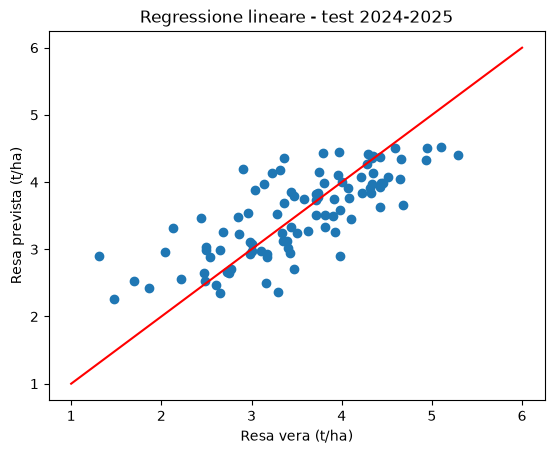

In [51]:
# Creare un grafico che confronti la resa prevista con la resa vera
plt.scatter(y_test, previsioni)
plt.plot([1, 6], [1, 6], color="red")
plt.xlabel("Resa vera (t/ha)")
plt.ylabel("Resa prevista (t/ha)")
plt.title("Regressione lineare - test 2024-2025")
plt.savefig("previsioni_vs_reali.png", dpi=150, bbox_inches="tight")
plt.show()

# Conclusioni
- Il modello stima la resa a fine aprile con un errore medio di 0,42 t/ha, contro 0,71 t/ha della semplice media degli anni passati (-40%). La Random Forest non migliora il risultato, quindi è stata scelta la regressione lineare, più semplice da interpretare.
- Secondo il modello utilizzato 100 mm di pioggia in più tra novembre e aprile sono associati a 0,33 t/ha di resa in più, e 20 kg di azoto in più a 0,06 t/ha. A parità di altre condizioni, 0,1 di NDVI in più ad aprile è associato a 0,28 t/ha di resa in più: per questo l'NDVI di aprile è un buon segnale precoce della resa. I campi seminati a Iride e Marco Aurelio hanno una resa più alta, rispettivamente di 0,19 e 0,15 t/ha rispetto a quelli seminati ad Antalis. I campi su suolo franco hanno in media una resa più alta di 0,45 t/ha rispetto a quelli su suolo argilloso, quelli su suolo sabbioso hanno una resa più bassa di 0,32 t/ha.
- Il modello tende a sovrastimare le rese più basse e a sottostimare quelle più alte: le previsioni per i campi con rese estreme vanno lette con più cautela.
- Il modello non conosce il meteo successivo ad aprile, come il caldo di maggio durante il riempimento della granella, che spiega parte dell'errore. I coefficienti indicano associazioni, non effetti causali: per valutare l'effetto reale dell'azoto o della varietà servono prove in campo.